In [1]:
import torch
from torch import nn
from torchvision import transforms
from PIL import Image 

class RedTomate (nn.Module):
    def __init__(self):
        super().__init__()
        self .extractor = nn.Sequential(
            nn. Conv2d(3, 16, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self .clasificador = nn.Sequential(
            nn.Flatten(),
            nn. Linear(32*16*16,10),
            )

    def forward(self, x):
        x = self.extractor(x)
        x = self.clasificador(x)
        return x
NOMBRES=[
     "Mancha bacteriana",
    "Tizón temprano",
    "Tizón tardío",
    "Moho de la hoja",
    "Mancha por Septoria",
    "Arañuela roja",
    "Mancha diana",
    "Virus del rizado amarillo",
    "Virus del mosaico",
    "Hoja sana",
]

red = RedTomate()
red.load_state_dict(torch.load("../modelos/red_tomate.pt"))
red.eval()

transformacion= transforms.Compose([
    transforms .Resize((64,64)),
    transforms.ToTensor(),
])


# LA FUNCION QUE PREDICE

In [2]:
def predecir(ruta):
    imagen = Image.open(ruta).convert("RGB")
    x = transformacion(imagen).unsqueeze(0) #unsqueeze(0) agrega una dimensión adelante: la foto pasa de [3, 64, 64] a [1, 3, 64, 64]

    with torch.no_grad():
        salida = red(x)

    probabilidades = torch.softmax(salida, dim=1)[0]
    mejores = probabilidades.topk(3) #Tres clases mas probables

    resultado = []
    for p, i in zip(mejores.values.tolist(), mejores.indices.tolist()):
        resultado.append((NOMBRES[i], p))
    return imagen, resultado

# FOTOS QUE NUNCA VIO

In [3]:
from torchvision import datasets
from torch.utils.data import random_split

datos = datasets.ImageFolder("../data/tomate")
_, _, prueba = random_split(datos, [0.8, 0.1, 0.1], generator=torch.Generator().manual_seed(42))
rutas_prueba = [datos.samples[i][0] for i in prueba.indices]

print(len(rutas_prueba))

#datos.samples es la lista de todas las fotos con su ruta, y prueba.indices dice cuáles le tocaron a la prueba.

1601


# LA DEMOSTRACION

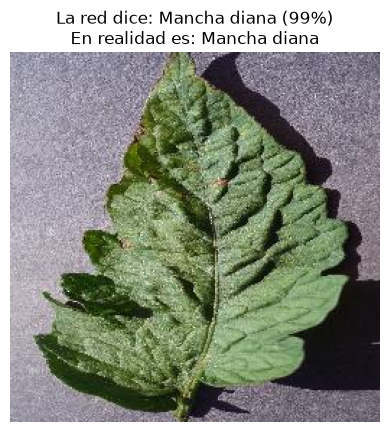

Mancha diana: 99.2%
Hoja sana: 0.8%
Tizón tardío: 0.0%


In [4]:
import random
import matplotlib.pyplot as plt
from pathlib import Path

ruta = random.choice(rutas_prueba) # es el nombre de la carpeta de la foto, o sea su clase real
imagen, resultado = predecir(ruta)
clase_real = NOMBRES[datos.class_to_idx[Path(ruta).parent.name]]

plt.imshow(imagen)
plt.axis("off")
plt.title(f"La red dice: {resultado[0][0]} ({resultado[0][1]:.0%})\nEn realidad es: {clase_real}")
plt.show()

for nombre, p in resultado:
    print(f"{nombre}: {p:.1%}")

# GRADIO APLICACION  HTTP://127.0.0.1:7860

In [ ]:
import gradio as gr
gr.close_all()
def clasificar(imagen):
    x = transformacion(imagen.convert("RGB")).unsqueeze(0)
    with torch.no_grad():
        probabilidades = torch.softmax(red(x), dim=1)[0]
    return {NOMBRES[i]: float(p) for i, p in enumerate(probabilidades)}

ejemplos = [[ruta] for ruta in random.sample(rutas_prueba, 6)]

demo = gr.Interface(
    fn=clasificar,
    inputs=gr.Image(type="pil", label="Foto de la hoja"),
    outputs=gr.Label(num_top_classes=3, label="Diagnóstico"),
    title="Detector de enfermedades en hojas de tomate",
    description=(
        "Subí la foto de una hoja de tomate y la red indica qué enfermedad tiene.\n\n"
        "**Aviso:** el modelo fue entrenado con fotos de laboratorio: una hoja sola, sobre fondo liso "
        "y con buena luz. Con fotos de campo (varias hojas, fondo de tierra, sol directo) puede "
        "equivocarse aunque muestre 100% de seguridad. No reemplaza el diagnóstico de un especialista."
    ),
    examples=ejemplos,
    flagging_mode="never",
)
demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
